# Lesson 3.4: The Normal Distribution

Use the heights of adult men (mean 69.1 in, SD 2.9 in) to find the share shorter than 66 inches and the height of the 90th percentile.

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Describe the bell curve

A normal distribution is fixed by two numbers: its centre (the mean) and its width (the standard deviation). SciPy bundles both into one object we can ask questions of.

In [1]:
from scipy import stats

mean, sd = 69.1, 2.9
heights = stats.norm(loc=mean, scale=sd)

print('median =', heights.median())

median = 69.1


## 2. Share shorter than 66 inches

cdf gives the area under the curve to the left of a value, which is the probability of being at or below it. The z-score says how many standard deviations 66 is below the mean.

In [2]:
z = (66 - mean) / sd
share = heights.cdf(66)

print(f'z = {z:.2f}')
print(f'P(height < 66) = {share:.4f}')

z = -1.07
P(height < 66) = 0.1425


## 3. The 90th percentile

ppf runs the other way: give it an area and it returns the value. Only 10% of men are taller than the height it prints.

In [3]:
p90 = heights.ppf(0.90)

print(f'90th percentile = {p90:.1f} inches')

90th percentile = 72.8 inches


## 4. Check the 68-95-99.7 rule

The empirical rule says about 68%, 95% and 99.7% of values lie within 1, 2 and 3 standard deviations of the mean. We check it with the standard normal curve.

In [4]:
for k in (1, 2, 3):
    inside = stats.norm.cdf(k) - stats.norm.cdf(-k)
    print(f'within {k} SD: {inside:.4f}')

within 1 SD: 0.6827
within 2 SD: 0.9545
within 3 SD: 0.9973


## 5. Draw it

The shaded area is the probability we computed for men shorter than 66 inches. A picture makes it clear that probabilities are areas.

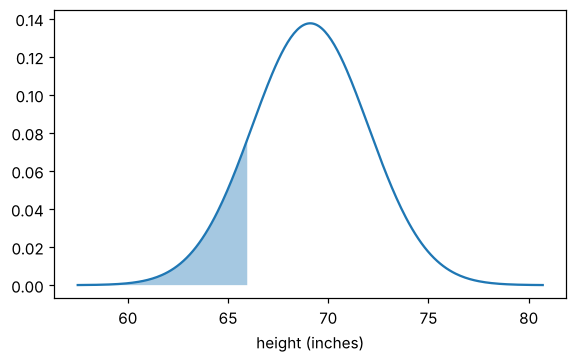

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(mean - 4 * sd, mean + 4 * sd, 300)
plt.figure(figsize=(6, 3.4))
plt.plot(x, heights.pdf(x))
plt.fill_between(x, heights.pdf(x), where=x < 66, alpha=0.4)
plt.xlabel('height (inches)')
plt.show()

## Try this

- Change the cut-off to 72 inches and predict whether the share below it is above or below 50%, then run it.
- Find the heights that mark the middle 95% of men with heights.ppf(0.025) and heights.ppf(0.975). How do they compare with mean plus or minus 2 SD?

## The same idea in R, SPSS and Stata

**R**

```r
pnorm(66, mean = 69.1, sd = 2.9)
qnorm(0.90, mean = 69.1, sd = 2.9)
pnorm(1) - pnorm(-1)
pnorm(2) - pnorm(-2)
```

**SPSS** (Transform > Compute Variable (use the CDF.NORMAL and IDF.NORMAL functions))

```
DATA LIST FREE / dummy.
BEGIN DATA
1
END DATA.
COMPUTE p_below_66 = CDF.NORMAL(66, 69.1, 2.9).
COMPUTE height_p90 = IDF.NORMAL(0.90, 69.1, 2.9).
COMPUTE within_1sd = CDF.NORMAL(1, 0, 1) - CDF.NORMAL(-1, 0, 1).
FORMATS p_below_66 height_p90 within_1sd (F8.4).
LIST p_below_66 height_p90 within_1sd.
```

**Stata**

```
display normal((66 - 69.1) / 2.9)
display 69.1 + 2.9 * invnormal(0.90)
display normal(1) - normal(-1)
```